# Notebook 03 - Random Forest

Objective: train and evaluate a Random Forest churn model using only the current tree preprocessing branch from `run_pipeline(force_ingestion=False, use_database=False)`.

Scope rules for this notebook:

- Use only `outputs['tree']` for Random Forest training and evaluation.
- Print logistic branch shapes only for comparison.
- Keep actual `X_train`, `X_val`, and `X_test` feature columns unchanged before fitting.
- Use validation data for Threshold Sensitivity Analysis and threshold selection.
- Use test data only after the threshold has been selected from validation data.
- Use feature display mapping only for report tables and chart labels.
- Save tables to `Source/reports/data_reports/`.
- Save figures to `Source/reports/figures/`.

## 1. Imports

In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

warnings.filterwarnings('default')
pd.set_option('display.max_columns', 140)
pd.set_option('display.max_rows', 140)

RANDOM_STATE = 42
DEFAULT_THRESHOLD = 0.50
TARGET_RECALL = 0.85
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)


## 2. Path and Folder Checks

In [2]:
def find_source_root(start_path: Path) -> Path:
    candidates = [start_path, *start_path.parents]
    for candidate in candidates:
        direct_match = candidate.name == 'Source' and (candidate / 'src' / 'main.py').exists()
        nested_match = (candidate / 'Source' / 'src' / 'main.py').exists()
        if direct_match:
            return candidate
        if nested_match:
            return candidate / 'Source'
    raise FileNotFoundError('Could not locate the Source project root from the current working directory.')


CURRENT_WORKING_DIR = Path.cwd().resolve()
SOURCE_ROOT = find_source_root(CURRENT_WORKING_DIR)
REPO_ROOT = SOURCE_ROOT.parent
TARGET_NOTEBOOK_PATH = SOURCE_ROOT / 'notebooks' / '03_tree_models_train.ipynb'

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print('Current working directory:', CURRENT_WORKING_DIR)
print('Source project root:', SOURCE_ROOT)
print('Target notebook path:', TARGET_NOTEBOOK_PATH)

from Source.src.path import (
    DATA_REPORTS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    NOTEBOOKS_DIR,
    PROJECT_ROOT,
    REPORTS_DIR,
    TEST_DATA_FILE,
    TRAIN_DATA_FILE,
    VALIDATION_DATA_FILE,
)
from Source.src.utils.feature_display import (
    build_feature_mapping_table,
    get_category_display_name,
)

path_checks = pd.DataFrame(
    [
        {'name': 'PROJECT_ROOT', 'path': PROJECT_ROOT, 'exists': PROJECT_ROOT.exists(), 'type': 'directory'},
        {'name': 'NOTEBOOKS_DIR', 'path': NOTEBOOKS_DIR, 'exists': NOTEBOOKS_DIR.exists(), 'type': 'directory'},
        {'name': 'REPORTS_DIR', 'path': REPORTS_DIR, 'exists': REPORTS_DIR.exists(), 'type': 'directory'},
        {'name': 'DATA_REPORTS_DIR', 'path': DATA_REPORTS_DIR, 'exists': DATA_REPORTS_DIR.exists(), 'type': 'directory'},
        {'name': 'FIGURES_DIR', 'path': FIGURES_DIR, 'exists': FIGURES_DIR.exists(), 'type': 'directory'},
        {'name': 'MODELS_DIR', 'path': MODELS_DIR, 'exists': MODELS_DIR.exists(), 'type': 'directory'},
        {'name': 'TRAIN_DATA_FILE', 'path': TRAIN_DATA_FILE, 'exists': TRAIN_DATA_FILE.exists(), 'type': 'checkpoint file'},
        {'name': 'VALIDATION_DATA_FILE', 'path': VALIDATION_DATA_FILE, 'exists': VALIDATION_DATA_FILE.exists(), 'type': 'checkpoint file'},
        {'name': 'TEST_DATA_FILE', 'path': TEST_DATA_FILE, 'exists': TEST_DATA_FILE.exists(), 'type': 'checkpoint file'},
    ]
)
path_checks['path'] = path_checks['path'].astype(str)
display(path_checks)

missing_required_dirs = path_checks[(path_checks['type'] == 'directory') & (~path_checks['exists'])]
missing_checkpoints = path_checks[(path_checks['type'] == 'checkpoint file') & (~path_checks['exists'])]

if not missing_required_dirs.empty:
    raise FileNotFoundError(f'Missing required project directories: {missing_required_dirs["path"].tolist()}')

if not missing_checkpoints.empty:
    raise FileNotFoundError(
        'Missing checkpoint files. Stopping before run_pipeline() so ingestion is not triggered: '
        f'{missing_checkpoints["path"].tolist()}'
    )

print('All required folders and checkpoint files exist. Safe to call run_pipeline without ingestion.')


Current working directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\notebooks
Refactor project root: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2
Target notebook path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\notebooks\03_tree_models_train.ipynb
Legacy root notebook path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\notebooks\03_tree_models_train.ipynb
Legacy root notebook exists: True


,name,path,exists,type
0,PROJECT_ROOT,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
1,NOTEBOOKS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
2,REPORTS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
3,DATA_REPORTS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
4,FIGURES_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
5,MODELS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
6,TRAIN_DATA_FILE,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,checkpoint file
7,VALIDATION_DATA_FILE,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,checkpoint file
8,TEST_DATA_FILE,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,checkpoint file


All required folders and checkpoint files exist. Safe to call run_pipeline without ingestion.


## 3. Notebook-Local Helpers

In [3]:
def display_and_save_table(df: pd.DataFrame, filename: str, description: str | None = None) -> Path:
    output_path = DATA_REPORTS_DIR / filename
    DATA_REPORTS_DIR.mkdir(parents=True, exist_ok=True)
    if description:
        print(description)
    display(df)
    df.to_csv(output_path, index=False)
    print('Table shape:', df.shape)
    print('Saved table:', output_path)
    return output_path


def save_current_figure(filename: str) -> Path:
    output_path = FIGURES_DIR / filename
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print('Saved figure:', output_path)
    plt.show()
    return output_path


def evaluate_binary_classifier(
    y_true: pd.Series | np.ndarray,
    y_proba: np.ndarray,
    threshold: float,
    model_name: str = 'Random Forest',
    split_name: str = 'validation',
) -> pd.DataFrame:
    y_true_array = np.asarray(y_true).astype(int)
    y_pred = (np.asarray(y_proba) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true_array, y_pred, labels=[0, 1]).ravel()
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    unique_classes = np.unique(y_true_array)
    roc_auc = roc_auc_score(y_true_array, y_proba) if len(unique_classes) == 2 else np.nan
    pr_auc = average_precision_score(y_true_array, y_proba) if len(unique_classes) == 2 else np.nan

    return pd.DataFrame(
        [
            {
                'Model': model_name,
                'Split': split_name,
                'Threshold': float(threshold),
                'Accuracy': accuracy_score(y_true_array, y_pred),
                'Precision': precision_score(y_true_array, y_pred, zero_division=0),
                'Recall': recall_score(y_true_array, y_pred, zero_division=0),
                'F1_Score': f1_score(y_true_array, y_pred, zero_division=0),
                'ROC_AUC': roc_auc,
                'PR_AUC': pr_auc,
                'TP': int(tp),
                'FP': int(fp),
                'TN': int(tn),
                'FN': int(fn),
                'False_Positive_Rate': fpr,
                'False_Negative_Rate': fnr,
            }
        ]
    )


def build_confusion_matrix_table(
    y_true: pd.Series | np.ndarray,
    y_pred: np.ndarray,
    split_name: str,
    threshold: float,
) -> pd.DataFrame:
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return pd.DataFrame(
        [
            {'Split': split_name, 'Threshold': threshold, 'Actual': 0, 'Predicted': 0, 'Count': int(tn)},
            {'Split': split_name, 'Threshold': threshold, 'Actual': 0, 'Predicted': 1, 'Count': int(fp)},
            {'Split': split_name, 'Threshold': threshold, 'Actual': 1, 'Predicted': 0, 'Count': int(fn)},
            {'Split': split_name, 'Threshold': threshold, 'Actual': 1, 'Predicted': 1, 'Count': int(tp)},
        ]
    )


def build_classification_report_table(
    y_true: pd.Series | np.ndarray,
    y_pred: np.ndarray,
    split_name: str,
    threshold: float,
) -> pd.DataFrame:
    report = classification_report(y_true, y_pred, labels=[0, 1], output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).T.reset_index().rename(columns={'index': 'Class'})
    report_df.insert(0, 'Split', split_name)
    report_df.insert(1, 'Threshold', threshold)
    return report_df


def scan_thresholds(
    y_true: pd.Series | np.ndarray,
    y_proba: np.ndarray,
    thresholds: np.ndarray,
    target_recall: float = TARGET_RECALL,
) -> pd.DataFrame:
    rows = []
    for threshold in thresholds:
        metrics = evaluate_binary_classifier(
            y_true=y_true,
            y_proba=y_proba,
            threshold=float(threshold),
            split_name='validation',
        ).iloc[0].to_dict()
        metrics['Meets_Recall_Target'] = metrics['Recall'] >= target_recall
        rows.append(metrics)
    return pd.DataFrame(rows)


def select_threshold(
    threshold_df: pd.DataFrame,
    target_recall: float = TARGET_RECALL,
    close_f1_tolerance: float = 0.001,
) -> tuple[float, pd.DataFrame]:
    candidates = threshold_df[threshold_df['Recall'] >= target_recall].copy()
    if not candidates.empty:
        best_f1 = candidates['F1_Score'].max()
        near_best = candidates[candidates['F1_Score'] >= best_f1 - close_f1_tolerance].copy()
        selected = near_best.sort_values(
            ['Precision', 'F1_Score', 'Threshold'],
            ascending=[False, False, False],
        ).iloc[0]
        target_met = True
        rule = 'Recall target met; selected highest F1-score, with near ties resolved by higher precision.'
    else:
        selected = threshold_df.sort_values(
            ['Recall', 'F1_Score', 'Precision'],
            ascending=[False, False, False],
        ).iloc[0]
        target_met = False
        rule = 'Recall target not met; selected highest recall, then highest F1-score and precision.'

    selected_df = selected.to_frame().T.reset_index(drop=True)
    selected_df['Target_Recall'] = target_recall
    selected_df['Recall_Target_Met'] = target_met
    selected_df['Selection_Rule'] = rule
    return float(selected['Threshold']), selected_df


def plot_confusion_matrix_from_values(
    y_true: pd.Series | np.ndarray,
    y_pred: np.ndarray,
    title: str,
) -> None:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    ax.figure.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(title)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels([get_category_display_name('Churn', 0), get_category_display_name('Churn', 1)])
    ax.set_yticklabels([get_category_display_name('Churn', 0), get_category_display_name('Churn', 1)])
    threshold_value = cm.max() / 2 if cm.size else 0
    for row_index in range(cm.shape[0]):
        for col_index in range(cm.shape[1]):
            color = 'white' if cm[row_index, col_index] > threshold_value else 'black'
            ax.text(col_index, row_index, int(cm[row_index, col_index]), ha='center', va='center', color=color)


def plot_threshold_sensitivity(threshold_df: pd.DataFrame, selected_threshold: float) -> None:
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(threshold_df['Threshold'], threshold_df['Precision'], label='Precision', linewidth=2)
    ax.plot(threshold_df['Threshold'], threshold_df['Recall'], label='Recall', linewidth=2)
    ax.plot(threshold_df['Threshold'], threshold_df['F1_Score'], label='F1-score', linewidth=2)
    ax.axhline(TARGET_RECALL, color='gray', linestyle='--', linewidth=1.5, label=f'Target recall {TARGET_RECALL:.2f}')
    ax.axvline(selected_threshold, color='black', linestyle=':', linewidth=1.8, label=f'Selected threshold {selected_threshold:.2f}')
    ax.set_title('Threshold Sensitivity Analysis - Validation')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('Score')
    ax.set_xlim(0.05, 0.95)
    ax.set_ylim(0.0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(loc='best')


def plot_roc_curve(y_true: pd.Series | np.ndarray, y_proba: np.ndarray) -> None:
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = roc_auc_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(fpr, tpr, linewidth=2, label=f'ROC-AUC = {roc_auc:.4f}')
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5)
    ax.set_title('ROC Curve - Validation')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')


def plot_precision_recall_curve(y_true: pd.Series | np.ndarray, y_proba: np.ndarray) -> None:
    precision, recall, _ = precision_recall_curve(y_true, y_proba)
    pr_auc = average_precision_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(recall, precision, linewidth=2, label=f'PR-AUC = {pr_auc:.4f}')
    ax.set_title('Precision-Recall Curve - Validation')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(loc='best')


def build_feature_importance_table(model: RandomForestClassifier, feature_names: pd.Index) -> pd.DataFrame:
    importance_df = build_feature_mapping_table(feature_names).copy()
    importance_df['Importance'] = model.feature_importances_
    importance_df = importance_df.sort_values('Importance', ascending=False).reset_index(drop=True)
    importance_df['Rank'] = np.arange(1, len(importance_df) + 1)
    return importance_df[
        [
            'Feature_Code',
            'Feature_Display_Name',
            'Base_Feature',
            'Base_Feature_Display_Name',
            'Encoded_Category',
            'Encoded_Category_Display_Name',
            'Feature_Group',
            'Feature_Type',
            'Importance',
            'Rank',
        ]
    ]


def plot_feature_importance_barh(importance_df: pd.DataFrame, title: str) -> None:
    fig, ax = plt.subplots(figsize=(10, 7))
    plot_df = importance_df.iloc[::-1].copy()
    ax.barh(plot_df['Feature_Display_Name'], plot_df['Importance'], color='#4c78a8')
    ax.set_title(title)
    ax.set_xlabel('Importance')
    ax.set_ylabel('Feature')
    ax.grid(axis='x', alpha=0.25)


def plot_cumulative_feature_importance(importance_df: pd.DataFrame) -> None:
    plot_df = importance_df.sort_values('Rank').copy()
    plot_df['Cumulative_Importance'] = plot_df['Importance'].cumsum()
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(plot_df['Rank'], plot_df['Cumulative_Importance'], marker='o', linewidth=2)
    ax.set_title('Cumulative Random Forest Feature Importance')
    ax.set_xlabel('Feature rank')
    ax.set_ylabel('Cumulative importance')
    ax.set_ylim(0.0, 1.05)
    ax.grid(alpha=0.3)


## 4. Load Preprocessing Outputs Using `run_pipeline()`

In [4]:
from Source.src.main import run_pipeline

result = run_pipeline(force_ingestion=False, use_database=False)
builder = result['builder']
outputs = result['outputs']

tree_train = outputs['tree']['train']
tree_val = outputs['tree']['validation']
tree_test = outputs['tree']['test']

logistic_train = outputs['logistic']['train']
logistic_val = outputs['logistic']['validation']
logistic_test = outputs['logistic']['test']

print('Tree branch shapes:')
print('train:', tree_train.shape)
print('validation:', tree_val.shape)
print('test:', tree_test.shape)

print('\nLogistic branch shapes for comparison only:')
print('train:', logistic_train.shape)
print('validation:', logistic_val.shape)
print('test:', logistic_test.shape)


2026-07-08 14:25:34,475 - main - [INFO] - Refactored churn pipeline orchestration started.
2026-07-08 14:25:34,476 - main - [INFO] - Run options: force_ingestion=False, use_database=False, view_name=None
2026-07-08 14:25:34,477 - main - [INFO] - Train checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\train_df.csv
2026-07-08 14:25:34,478 - main - [INFO] - Validation checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\validation_df.csv
2026-07-08 14:25:34,479 - main - [INFO] - Test checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\test_df.csv
2026-07-08 14:25:34,480 - main - [INFO] - All checkpoint files exist; ingestion skipped.
2026-07-08 14:25:34,496 - main - [INFO] - Loaded train checkpoint shape: (4930, 16)
2026-07-08 14:25:34,497 - main - [INFO] - Loaded validation checkpoint shape: (1056,

All required project directories are available.
All required project directories are available.


2026-07-08 14:25:34,706 - main - [INFO] - Logistic train output shape: (4930, 28)
2026-07-08 14:25:34,707 - main - [INFO] - Logistic validation output shape: (1056, 28)
2026-07-08 14:25:34,707 - main - [INFO] - Logistic test output shape: (1057, 28)
2026-07-08 14:25:34,709 - main - [INFO] - Tree train output shape: (4930, 20)
2026-07-08 14:25:34,709 - main - [INFO] - Tree validation output shape: (1056, 20)
2026-07-08 14:25:34,710 - main - [INFO] - Tree test output shape: (1057, 20)
2026-07-08 14:25:34,711 - main - [INFO] - Preprocessing branch orchestration completed.
2026-07-08 14:25:34,712 - main - [INFO] - Refactored churn pipeline orchestration finished.


Tree branch shapes:
train: (4930, 20)
validation: (1056, 20)
test: (1057, 20)

Logistic branch shapes for comparison only:
train: (4930, 28)
validation: (1056, 28)
test: (1057, 28)


## 5. Tree Branch Sanity Checks

In [5]:
def display_tree_branch_checks(name: str, df: pd.DataFrame) -> None:
    print(f'{name} shape:', df.shape)
    print(f'{name} row count:', df.shape[0])
    print(f'{name} column count:', df.shape[1])
    print(f'{name} column names:')
    print(df.columns.tolist())
    print(f'{name} head:')
    display(df.head())

    dtype_summary = df.dtypes.astype(str).value_counts().rename_axis('dtype').reset_index(name='column_count')
    print(f'{name} dtypes summary:')
    display(dtype_summary)

    dtype_detail = df.dtypes.astype(str).rename('dtype').reset_index().rename(columns={'index': 'column'})
    display(dtype_detail)

    print(f'{name} ID exists:', 'ID' in df.columns)
    print(f'{name} Churn exists:', 'Churn' in df.columns)
    if 'ID' not in df.columns or 'Churn' not in df.columns:
        raise ValueError(f'{name} is missing ID or Churn.')

    object_columns = df.select_dtypes(include='object').columns.tolist()
    print(f'{name} object columns:', object_columns)

    missing_summary = df.isna().sum().rename('missing_count').reset_index().rename(columns={'index': 'column'})
    missing_summary['missing_rate'] = missing_summary['missing_count'] / len(df)
    print(f'{name} missing values summary:')
    display(missing_summary)
    print(f'{name} total missing values:', int(missing_summary['missing_count'].sum()))

    churn_distribution = df['Churn'].value_counts(dropna=False).rename_axis('Churn').reset_index(name='count')
    churn_distribution['share'] = churn_distribution['count'] / churn_distribution['count'].sum()
    print(f'{name} Churn class distribution:')
    display(churn_distribution)


for split_name, split_df in {
    'tree_train': tree_train,
    'tree_validation': tree_val,
    'tree_test': tree_test,
}.items():
    display_tree_branch_checks(split_name, split_df)


tree_train shape: (4930, 20)
tree_train row count: 4930
tree_train column count: 20
tree_train column names:
['ID', 'Churn', 'SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'tenure_group', 'service_diversity', 'monthly_charges_ratio', 'is_paperless_electronic']
tree_train head:


,ID,Churn,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaymentMethod,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,tenure_group,service_diversity,monthly_charges_ratio,is_paperless_electronic
0,7883-ROJOC,0,0,1.0,0.0,19,0.0,3.0,0.0,44.9,839.65,0.0,0.0,0.0,0.0,0.0,1.0,0,0.693781,0
1,3164-AALRN,1,0,0.0,0.0,5,1.0,3.0,1.0,70.0,347.40,0.0,0.0,0.0,1.0,0.0,0.0,1,1.081619,0
2,9821-POOTN,1,0,1.0,0.0,35,0.0,2.0,1.0,75.2,2576.20,1.0,0.0,0.0,0.0,0.0,2.0,0,1.161968,0
3,3259-QMXUN,0,0,1.0,0.0,58,2.0,2.0,1.0,86.1,4890.50,0.0,1.0,1.0,1.0,0.0,4.0,3,1.330392,0
4,1226-UDFZR,1,0,0.0,0.0,2,0.0,3.0,1.0,49.6,114.70,0.0,0.0,1.0,0.0,0.0,0.0,1,0.766404,0


tree_train dtypes summary:


,dtype,column_count
0,float64,14
1,int64,5
2,object,1


,column,dtype
0,ID,object
1,Churn,int64
2,SeniorCitizen,int64
3,Partner,float64
4,Dependents,float64
5,Tenure,int64
6,Contract,float64
7,PaymentMethod,float64
8,PaperlessBilling,float64
9,MonthlyCharges,float64


tree_train ID exists: True
tree_train Churn exists: True
tree_train object columns: ['ID']
tree_train missing values summary:


... (17 outputs left out)

tree_test ID exists: True
tree_test Churn exists: True
tree_test object columns: ['ID']
tree_test missing values summary:


,column,missing_count,missing_rate
0,ID,0,0.0
1,Churn,0,0.0
2,SeniorCitizen,0,0.0
3,Partner,0,0.0
4,Dependents,0,0.0
5,Tenure,0,0.0
6,Contract,0,0.0
7,PaymentMethod,0,0.0
8,PaperlessBilling,0,0.0
9,MonthlyCharges,0,0.0


tree_test total missing values: 0
tree_test Churn class distribution:


,Churn,count,share
0,0,776,0.734153
1,1,281,0.265847


## 6. X/y Split

In [6]:
X_train = tree_train.drop(columns=['ID', 'Churn'])
y_train = tree_train['Churn'].astype(int)

X_val = tree_val.drop(columns=['ID', 'Churn'])
y_val = tree_val['Churn'].astype(int)

X_test = tree_test.drop(columns=['ID', 'Churn'])
y_test = tree_test['Churn'].astype(int)

print('X_train.shape:', X_train.shape)
print('X_val.shape:', X_val.shape)
print('X_test.shape:', X_test.shape)
print('y_train.shape:', y_train.shape)
print('y_val.shape:', y_val.shape)
print('y_test.shape:', y_test.shape)

print('ID not in X_train.columns:', 'ID' not in X_train.columns)
print('Churn not in X_train.columns:', 'Churn' not in X_train.columns)
print('ID not in X_val.columns:', 'ID' not in X_val.columns)
print('Churn not in X_val.columns:', 'Churn' not in X_val.columns)
print('ID not in X_test.columns:', 'ID' not in X_test.columns)
print('Churn not in X_test.columns:', 'Churn' not in X_test.columns)

if any(column in X_train.columns for column in ['ID', 'Churn']):
    raise RuntimeError('X_train still contains ID or Churn.')
if any(column in X_val.columns for column in ['ID', 'Churn']):
    raise RuntimeError('X_val still contains ID or Churn.')
if any(column in X_test.columns for column in ['ID', 'Churn']):
    raise RuntimeError('X_test still contains ID or Churn.')

unexpected_object_columns = X_train.select_dtypes(include='object').columns.tolist()
print('Object columns in X_train:', unexpected_object_columns)
if unexpected_object_columns:
    raise TypeError(f'X_train contains object columns that Random Forest cannot consume directly: {unexpected_object_columns}')

print('X_train head:')
display(X_train.head())

print('y_train value counts:')
display(y_train.value_counts().rename_axis('Churn').reset_index(name='count'))


X_train.shape: (4930, 18)
X_val.shape: (1056, 18)
X_test.shape: (1057, 18)
y_train.shape: (4930,)
y_val.shape: (1056,)
y_test.shape: (1057,)
ID not in X_train.columns: True
Churn not in X_train.columns: True
ID not in X_val.columns: True
Churn not in X_val.columns: True
ID not in X_test.columns: True
Churn not in X_test.columns: True
Object columns in X_train: []
X_train head:


,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaymentMethod,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,tenure_group,service_diversity,monthly_charges_ratio,is_paperless_electronic
0,0,1.0,0.0,19,0.0,3.0,0.0,44.9,839.65,0.0,0.0,0.0,0.0,0.0,1.0,0,0.693781,0
1,0,0.0,0.0,5,1.0,3.0,1.0,70.0,347.40,0.0,0.0,0.0,1.0,0.0,0.0,1,1.081619,0
2,0,1.0,0.0,35,0.0,2.0,1.0,75.2,2576.20,1.0,0.0,0.0,0.0,0.0,2.0,0,1.161968,0
3,0,1.0,0.0,58,2.0,2.0,1.0,86.1,4890.50,0.0,1.0,1.0,1.0,0.0,4.0,3,1.330392,0
4,0,0.0,0.0,2,0.0,3.0,1.0,49.6,114.70,0.0,0.0,1.0,0.0,0.0,0.0,1,0.766404,0


y_train value counts:


,Churn,count
0,0,3622
1,1,1308


## 7. Train Random Forest

In [7]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_model.fit(X_train, y_train)

validation_proba = rf_model.predict_proba(X_val)[:, 1]
validation_pred_default = (validation_proba >= DEFAULT_THRESHOLD).astype(int)

print('Baseline Random Forest trained.')
print('Model parameters:', rf_model.get_params())
print('Validation probability array shape:', validation_proba.shape)
print('Validation default prediction threshold:', DEFAULT_THRESHOLD)


Baseline Random Forest trained.
Model parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 300, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Validation probability array shape: (1056,)
Validation default prediction threshold: 0.5


## 8. Default Validation Evaluation at Threshold 0.50

Validation metrics at default threshold 0.50


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate
0,Random Forest,validation,0.5,0.79072,0.629956,0.510714,0.564103,0.845214,0.645568,143,84,692,137,0.108247,0.489286


Table shape: (1, 15)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_default_threshold_validation_metrics.csv
Validation confusion matrix table at default threshold 0.50


,Split,Threshold,Actual,Predicted,Count
0,validation,0.5,0,0,692
1,validation,0.5,0,1,84
2,validation,0.5,1,0,137
3,validation,0.5,1,1,143


Table shape: (4, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_default_threshold_validation_confusion_matrix.csv
Validation classification report at default threshold 0.50


,Split,Threshold,Class,precision,recall,f1-score,support
0,validation,0.5,0,0.834741,0.891753,0.862305,776.00000
1,validation,0.5,1,0.629956,0.510714,0.564103,280.00000
2,validation,0.5,accuracy,0.790720,0.790720,0.790720,0.79072
3,validation,0.5,macro avg,0.732348,0.701233,0.713204,1056.00000
4,validation,0.5,weighted avg,0.780442,0.790720,0.783236,1056.00000


Table shape: (5, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_default_threshold_validation_classification_report.csv
Classification report at validation threshold 0.50:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86       776
           1       0.63      0.51      0.56       280

    accuracy                           0.79      1056
   macro avg       0.73      0.70      0.71      1056
weighted avg       0.78      0.79      0.78      1056

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\random_forest_01_validation_confusion_matrix_default_threshold.png


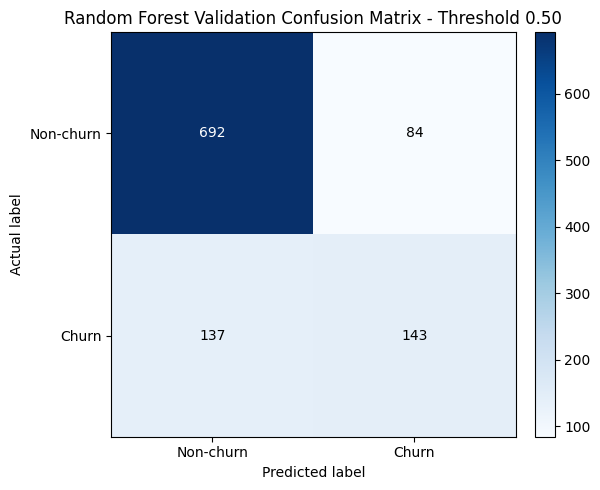

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/random_forest_01_validation_confusion_matrix_default_threshold.png')

In [8]:
default_validation_metrics = evaluate_binary_classifier(
    y_true=y_val,
    y_proba=validation_proba,
    threshold=DEFAULT_THRESHOLD,
    split_name='validation',
)
display_and_save_table(
    default_validation_metrics,
    'random_forest_default_threshold_validation_metrics.csv',
    'Validation metrics at default threshold 0.50',
)

default_validation_confusion_matrix = build_confusion_matrix_table(
    y_true=y_val,
    y_pred=validation_pred_default,
    split_name='validation',
    threshold=DEFAULT_THRESHOLD,
)
display_and_save_table(
    default_validation_confusion_matrix,
    'random_forest_default_threshold_validation_confusion_matrix.csv',
    'Validation confusion matrix table at default threshold 0.50',
)

default_validation_classification_report = build_classification_report_table(
    y_true=y_val,
    y_pred=validation_pred_default,
    split_name='validation',
    threshold=DEFAULT_THRESHOLD,
)
display_and_save_table(
    default_validation_classification_report,
    'random_forest_default_threshold_validation_classification_report.csv',
    'Validation classification report at default threshold 0.50',
)

print('Classification report at validation threshold 0.50:')
print(classification_report(y_val, validation_pred_default, zero_division=0))

plot_confusion_matrix_from_values(
    y_true=y_val,
    y_pred=validation_pred_default,
    title='Random Forest Validation Confusion Matrix - Threshold 0.50',
)
save_current_figure('random_forest_01_validation_confusion_matrix_default_threshold.png')


## 9. Threshold Sensitivity Analysis on Validation

Threshold Sensitivity Analysis on validation data


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Meets_Recall_Target
0,Random Forest,validation,0.05,0.537879,0.362797,0.982143,0.529865,0.845214,0.645568,275,483,293,5,0.622423,0.017857,True
1,Random Forest,validation,0.06,0.567235,0.377254,0.971429,0.543457,0.845214,0.645568,272,449,327,8,0.578608,0.028571,True
2,Random Forest,validation,0.07,0.589015,0.388081,0.953571,0.551653,0.845214,0.645568,267,421,355,13,0.542526,0.046429,True
3,Random Forest,validation,0.08,0.607955,0.398485,0.939286,0.559574,0.845214,0.645568,263,397,379,17,0.511598,0.060714,True
4,Random Forest,validation,0.09,0.621212,0.406832,0.935714,0.567100,0.845214,0.645568,262,382,394,18,0.492268,0.064286,True
5,Random Forest,validation,0.10,0.634470,0.415335,0.928571,0.573951,0.845214,0.645568,260,366,410,20,0.471649,0.071429,True
6,Random Forest,validation,0.11,0.649621,0.425743,0.921429,0.582393,0.845214,0.645568,258,348,428,22,0.448454,0.078571,True
7,Random Forest,validation,0.12,0.657197,0.430743,0.910714,0.584862,0.845214,0.645568,255,337,439,25,0.434278,0.089286,True
8,Random Forest,validation,0.13,0.670455,0.440767,0.903571,0.592506,0.845214,0.645568,253,321,455,27,0.413660,0.096429,True
9,Random Forest,validation,0.14,0.687500,0.454710,0.896429,0.603365,0.845214,0.645568,251,301,475,29,0.387887,0.103571,True


Table shape: (91, 16)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_threshold_sensitivity_validation.csv
Selected threshold validation metrics


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Meets_Recall_Target,Target_Recall,Recall_Target_Met,Selection_Rule
0,Random Forest,validation,0.17,0.706439,0.47093,0.867857,0.610553,0.845214,0.645568,243,273,503,37,0.351804,0.132143,True,0.85,True,"Recall target met; selected highest F1-score, ..."


Table shape: (1, 19)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_selected_threshold_validation_metrics.csv
Validation confusion matrix table at selected threshold


,Split,Threshold,Actual,Predicted,Count
0,validation,0.17,0,0,503
1,validation,0.17,0,1,273
2,validation,0.17,1,0,37
3,validation,0.17,1,1,243


Table shape: (4, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_selected_threshold_validation_confusion_matrix.csv
Validation classification report at selected threshold


,Split,Threshold,Class,precision,recall,f1-score,support
0,validation,0.17,0,0.931481,0.648196,0.764438,776.000000
1,validation,0.17,1,0.470930,0.867857,0.610553,280.000000
2,validation,0.17,accuracy,0.706439,0.706439,0.706439,0.706439
3,validation,0.17,macro avg,0.701206,0.758027,0.687495,1056.000000
4,validation,0.17,weighted avg,0.809366,0.706439,0.723635,1056.000000


Table shape: (5, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_selected_threshold_validation_classification_report.csv
Selected threshold from validation only: 0.17
Selected-threshold validation classification report:
              precision    recall  f1-score   support

           0       0.93      0.65      0.76       776
           1       0.47      0.87      0.61       280

    accuracy                           0.71      1056
   macro avg       0.70      0.76      0.69      1056
weighted avg       0.81      0.71      0.72      1056

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\random_forest_02_threshold_sensitivity_validation.png


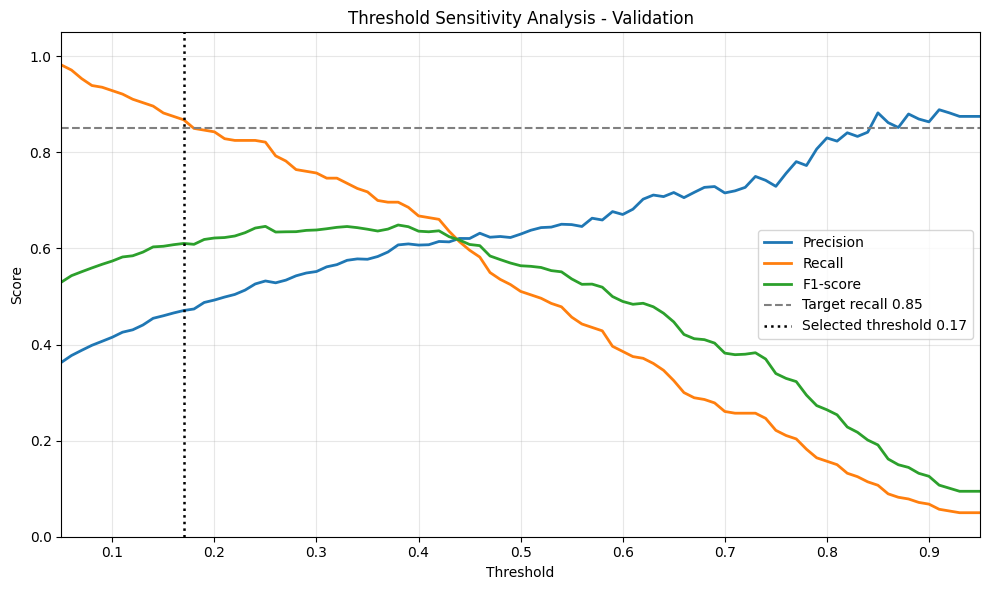

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/random_forest_02_threshold_sensitivity_validation.png')

In [9]:
threshold_sensitivity_validation = scan_thresholds(
    y_true=y_val,
    y_proba=validation_proba,
    thresholds=THRESHOLDS,
    target_recall=TARGET_RECALL,
)
display_and_save_table(
    threshold_sensitivity_validation,
    'random_forest_threshold_sensitivity_validation.csv',
    'Threshold Sensitivity Analysis on validation data',
)

selected_threshold, selected_threshold_validation_metrics = select_threshold(
    threshold_sensitivity_validation,
    target_recall=TARGET_RECALL,
)
display_and_save_table(
    selected_threshold_validation_metrics,
    'random_forest_selected_threshold_validation_metrics.csv',
    'Selected threshold validation metrics',
)

validation_pred_selected = (validation_proba >= selected_threshold).astype(int)

selected_validation_confusion_matrix = build_confusion_matrix_table(
    y_true=y_val,
    y_pred=validation_pred_selected,
    split_name='validation',
    threshold=selected_threshold,
)
display_and_save_table(
    selected_validation_confusion_matrix,
    'random_forest_selected_threshold_validation_confusion_matrix.csv',
    'Validation confusion matrix table at selected threshold',
)

selected_validation_classification_report = build_classification_report_table(
    y_true=y_val,
    y_pred=validation_pred_selected,
    split_name='validation',
    threshold=selected_threshold,
)
display_and_save_table(
    selected_validation_classification_report,
    'random_forest_selected_threshold_validation_classification_report.csv',
    'Validation classification report at selected threshold',
)

print('Selected threshold from validation only:', selected_threshold)
print('Selected-threshold validation classification report:')
print(classification_report(y_val, validation_pred_selected, zero_division=0))

plot_threshold_sensitivity(threshold_sensitivity_validation, selected_threshold)
save_current_figure('random_forest_02_threshold_sensitivity_validation.png')


## 10. Validation ROC and Precision-Recall Curves

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\random_forest_03_roc_curve_validation.png


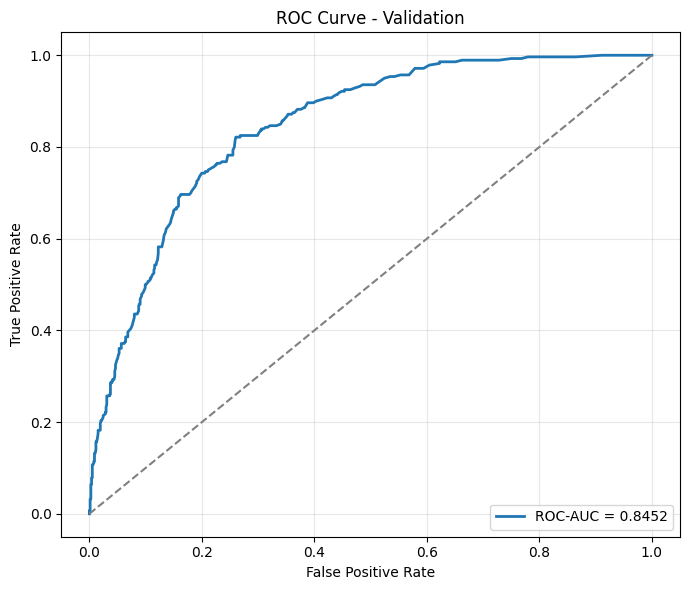

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\random_forest_04_precision_recall_curve_validation.png


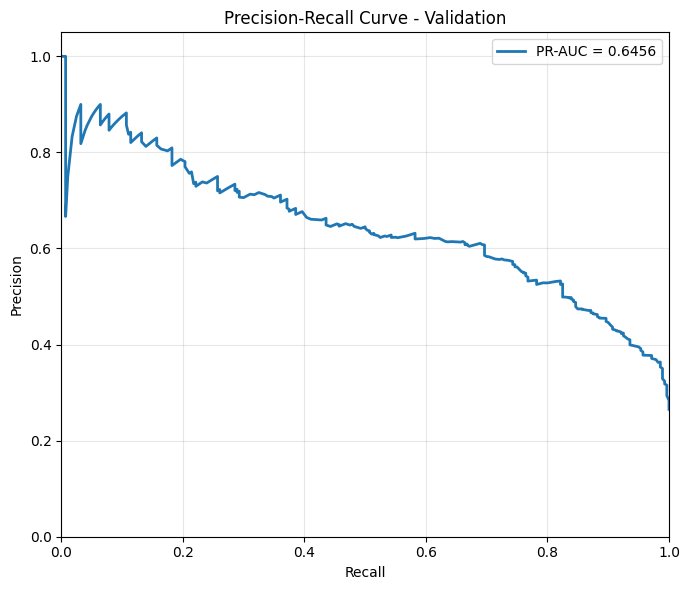

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/random_forest_04_precision_recall_curve_validation.png')

In [10]:
plot_roc_curve(y_val, validation_proba)
save_current_figure('random_forest_03_roc_curve_validation.png')

plot_precision_recall_curve(y_val, validation_proba)
save_current_figure('random_forest_04_precision_recall_curve_validation.png')


## 11. Final Test Evaluation Using Selected Threshold

Final test metrics using validation-selected threshold


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Threshold_Source
0,Random Forest,test,0.17,0.682119,0.448405,0.850534,0.587224,0.823009,0.616782,239,294,482,42,0.378866,0.149466,validation


Table shape: (1, 16)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_selected_threshold_test_metrics.csv
Final test confusion matrix table using validation-selected threshold


,Split,Threshold,Actual,Predicted,Count
0,test,0.17,0,0,482
1,test,0.17,0,1,294
2,test,0.17,1,0,42
3,test,0.17,1,1,239


Table shape: (4, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_selected_threshold_test_confusion_matrix.csv
Final test classification report using validation-selected threshold


,Split,Threshold,Class,precision,recall,f1-score,support
0,test,0.17,0,0.919847,0.621134,0.741538,776.000000
1,test,0.17,1,0.448405,0.850534,0.587224,281.000000
2,test,0.17,accuracy,0.682119,0.682119,0.682119,0.682119
3,test,0.17,macro avg,0.684126,0.735834,0.664381,1057.000000
4,test,0.17,weighted avg,0.794516,0.682119,0.700514,1057.000000


Table shape: (5, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_selected_threshold_test_classification_report.csv
Final test classification report using validation-selected threshold:
              precision    recall  f1-score   support

           0       0.92      0.62      0.74       776
           1       0.45      0.85      0.59       281

    accuracy                           0.68      1057
   macro avg       0.68      0.74      0.66      1057
weighted avg       0.79      0.68      0.70      1057

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\random_forest_05_test_confusion_matrix_selected_threshold.png


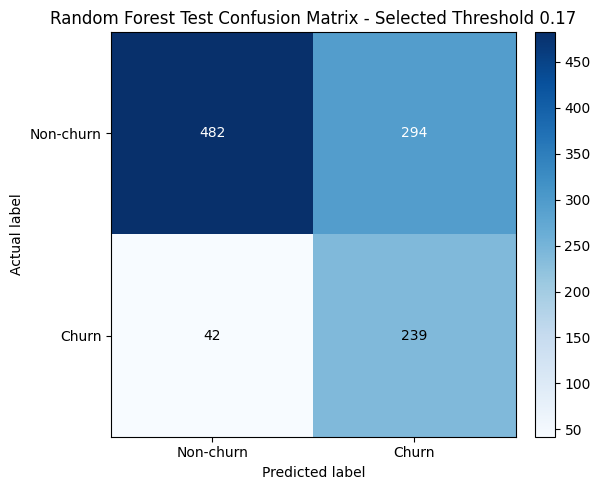

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/random_forest_05_test_confusion_matrix_selected_threshold.png')

In [11]:
test_proba = rf_model.predict_proba(X_test)[:, 1]
test_pred_selected = (test_proba >= selected_threshold).astype(int)

selected_threshold_test_metrics = evaluate_binary_classifier(
    y_true=y_test,
    y_proba=test_proba,
    threshold=selected_threshold,
    split_name='test',
)
selected_threshold_test_metrics['Threshold_Source'] = 'validation'
display_and_save_table(
    selected_threshold_test_metrics,
    'random_forest_selected_threshold_test_metrics.csv',
    'Final test metrics using validation-selected threshold',
)

selected_test_confusion_matrix = build_confusion_matrix_table(
    y_true=y_test,
    y_pred=test_pred_selected,
    split_name='test',
    threshold=selected_threshold,
)
display_and_save_table(
    selected_test_confusion_matrix,
    'random_forest_selected_threshold_test_confusion_matrix.csv',
    'Final test confusion matrix table using validation-selected threshold',
)

selected_test_classification_report = build_classification_report_table(
    y_true=y_test,
    y_pred=test_pred_selected,
    split_name='test',
    threshold=selected_threshold,
)
display_and_save_table(
    selected_test_classification_report,
    'random_forest_selected_threshold_test_classification_report.csv',
    'Final test classification report using validation-selected threshold',
)

print('Final test classification report using validation-selected threshold:')
print(classification_report(y_test, test_pred_selected, zero_division=0))

plot_confusion_matrix_from_values(
    y_true=y_test,
    y_pred=test_pred_selected,
    title=f'Random Forest Test Confusion Matrix - Selected Threshold {selected_threshold:.2f}',
)
save_current_figure('random_forest_05_test_confusion_matrix_selected_threshold.png')


## 12. Feature Importance Analysis

Tree branch feature name mapping


,Feature_Code,Feature_Display_Name,Base_Feature,Base_Feature_Display_Name,Encoded_Category,Encoded_Category_Display_Name,Feature_Group,Feature_Type,Is_Encoded
0,SeniorCitizen,Senior Citizen,SeniorCitizen,Senior Citizen,None,None,Customer Profile,Binary,False
1,Partner,Partner,Partner,Partner,None,None,Customer Profile,Binary,False
2,Dependents,Dependents,Dependents,Dependents,None,None,Customer Profile,Binary,False
3,Tenure,Tenure,Tenure,Tenure,None,None,Account / Contract,Numeric,False
4,Contract,Contract Type,Contract,Contract Type,None,None,Account / Contract,Categorical,False
5,PaymentMethod,Payment Method,PaymentMethod,Payment Method,None,None,Billing,Categorical,False
6,PaperlessBilling,Paperless Billing,PaperlessBilling,Paperless Billing,None,None,Billing,Binary,False
7,MonthlyCharges,Monthly Charges,MonthlyCharges,Monthly Charges,None,None,Charges,Numeric,False
8,TotalCharges,Total Charges,TotalCharges,Total Charges,None,None,Charges,Numeric,False
9,InternetService,Internet Service,InternetService,Internet Service,None,None,Service,Categorical,False


Table shape: (18, 9)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\feature_name_mapping_tree.csv
Random Forest feature importance table


,Feature_Code,Feature_Display_Name,Base_Feature,Base_Feature_Display_Name,Encoded_Category,Encoded_Category_Display_Name,Feature_Group,Feature_Type,Importance,Rank
0,TotalCharges,Total Charges,TotalCharges,Total Charges,None,None,Charges,Numeric,0.139764,1
1,monthly_charges_ratio,Monthly Charges Ratio,monthly_charges_ratio,Monthly Charges Ratio,None,None,Engineered,Numeric Engineered,0.136337,2
2,MonthlyCharges,Monthly Charges,MonthlyCharges,Monthly Charges,None,None,Charges,Numeric,0.135226,3
3,Tenure,Tenure,Tenure,Tenure,None,None,Account / Contract,Numeric,0.124372,4
4,Contract,Contract Type,Contract,Contract Type,None,None,Account / Contract,Categorical,0.121987,5
5,tenure_group,Tenure Group,tenure_group,Tenure Group,None,None,Engineered,Categorical Engineered,0.053841,6
6,Dependents,Dependents,Dependents,Dependents,None,None,Customer Profile,Binary,0.049052,7
7,PaymentMethod,Payment Method,PaymentMethod,Payment Method,None,None,Billing,Categorical,0.040458,8
8,InternetService,Internet Service,InternetService,Internet Service,None,None,Service,Categorical,0.038583,9
9,service_diversity,Service Diversity Score,service_diversity,Service Diversity Score,None,None,Engineered,Numeric Engineered,0.034653,10


Table shape: (18, 10)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_feature_importance.csv
Top Random Forest feature importance table


,Feature_Code,Feature_Display_Name,Base_Feature,Base_Feature_Display_Name,Encoded_Category,Encoded_Category_Display_Name,Feature_Group,Feature_Type,Importance,Rank
0,TotalCharges,Total Charges,TotalCharges,Total Charges,None,None,Charges,Numeric,0.139764,1
1,monthly_charges_ratio,Monthly Charges Ratio,monthly_charges_ratio,Monthly Charges Ratio,None,None,Engineered,Numeric Engineered,0.136337,2
2,MonthlyCharges,Monthly Charges,MonthlyCharges,Monthly Charges,None,None,Charges,Numeric,0.135226,3
3,Tenure,Tenure,Tenure,Tenure,None,None,Account / Contract,Numeric,0.124372,4
4,Contract,Contract Type,Contract,Contract Type,None,None,Account / Contract,Categorical,0.121987,5
5,tenure_group,Tenure Group,tenure_group,Tenure Group,None,None,Engineered,Categorical Engineered,0.053841,6
6,Dependents,Dependents,Dependents,Dependents,None,None,Customer Profile,Binary,0.049052,7
7,PaymentMethod,Payment Method,PaymentMethod,Payment Method,None,None,Billing,Categorical,0.040458,8
8,InternetService,Internet Service,InternetService,Internet Service,None,None,Service,Categorical,0.038583,9
9,service_diversity,Service Diversity Score,service_diversity,Service Diversity Score,None,None,Engineered,Numeric Engineered,0.034653,10


Table shape: (15, 10)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\random_forest_top_feature_importance.csv
Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\random_forest_06_top_feature_importance.png


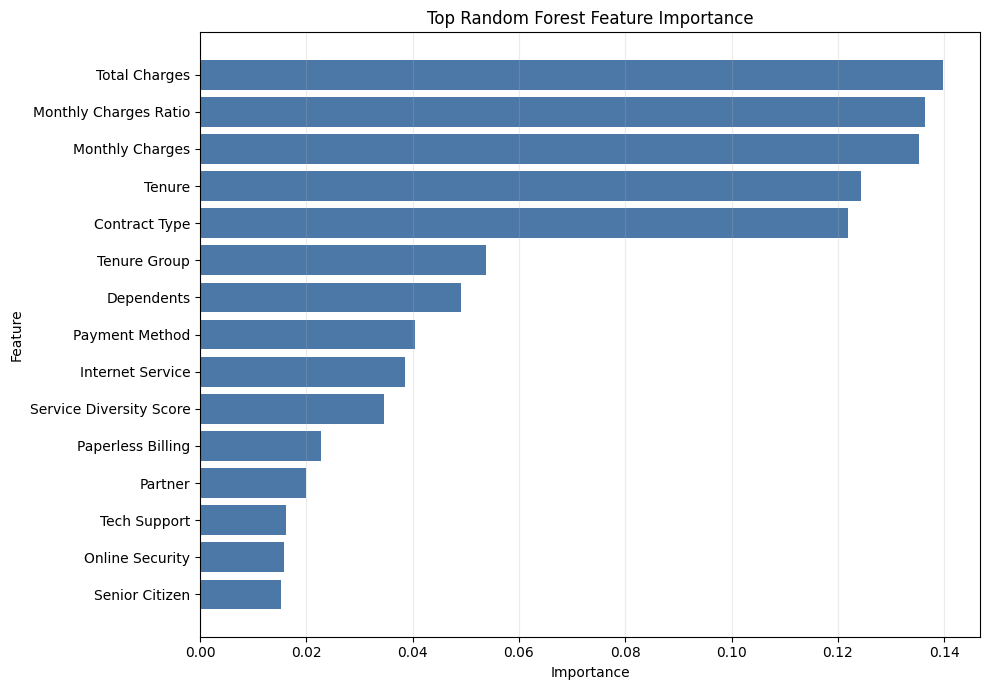

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\random_forest_07_cumulative_feature_importance.png


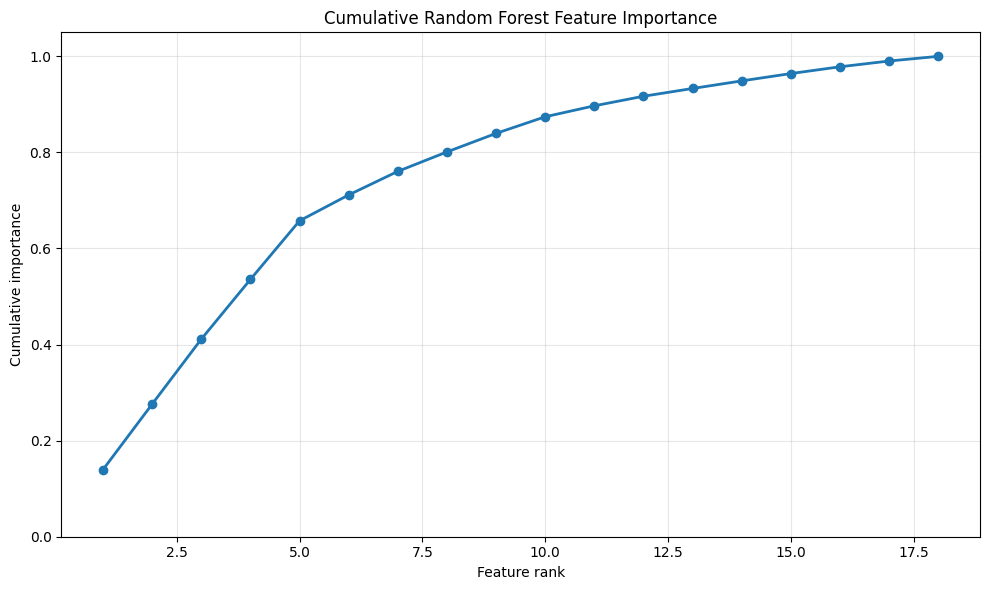

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/random_forest_07_cumulative_feature_importance.png')

In [12]:
feature_name_mapping_tree = build_feature_mapping_table(X_train.columns)
display_and_save_table(
    feature_name_mapping_tree,
    'feature_name_mapping_tree.csv',
    'Tree branch feature name mapping',
)

random_forest_feature_importance = build_feature_importance_table(rf_model, X_train.columns)
display_and_save_table(
    random_forest_feature_importance,
    'random_forest_feature_importance.csv',
    'Random Forest feature importance table',
)

random_forest_top_feature_importance = random_forest_feature_importance.head(15).reset_index(drop=True)
display_and_save_table(
    random_forest_top_feature_importance,
    'random_forest_top_feature_importance.csv',
    'Top Random Forest feature importance table',
)

plot_feature_importance_barh(
    random_forest_top_feature_importance,
    'Top Random Forest Feature Importance',
)
save_current_figure('random_forest_06_top_feature_importance.png')

plot_cumulative_feature_importance(random_forest_feature_importance)
save_current_figure('random_forest_07_cumulative_feature_importance.png')


## 13. Final Notebook Summary

In [13]:
print('Notebook 03 Random Forest summary')
print('Pipeline call: run_pipeline(force_ingestion=False, use_database=False)')
print('Training branch used: outputs[\'tree\'] only')
print('Tree train shape:', tree_train.shape)
print('Tree validation shape:', tree_val.shape)
print('Tree test shape:', tree_test.shape)
print('X_train shape:', X_train.shape)
print('X_val shape:', X_val.shape)
print('X_test shape:', X_test.shape)
print('Selected validation threshold:', selected_threshold)
print('Validation-selected threshold used for final test evaluation.')
print('Feature importance uses actual trained Random Forest feature columns.')
print('CSV outputs directory:', DATA_REPORTS_DIR)
print('Figure outputs directory:', FIGURES_DIR)


Notebook 03 Random Forest summary
Pipeline call: run_pipeline(force_ingestion=False, use_database=False)
Training branch used: outputs['tree'] only
Tree train shape: (4930, 20)
Tree validation shape: (1056, 20)
Tree test shape: (1057, 20)
X_train shape: (4930, 18)
X_val shape: (1056, 18)
X_test shape: (1057, 18)
Selected validation threshold: 0.17
Validation-selected threshold used for final test evaluation.
Feature importance uses actual trained Random Forest feature columns.
CSV outputs directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports
Figure outputs directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures
